# 08 – ML Setup: Validation Scheme, Metrics and Leakage Checks (S8)

**Course section:** ML I — terminology, holdout and k-fold cross-validation, success metrics, bias–variance trade-off, parameters vs hyperparameters.

**Goal:** fix *how* every model in S9–S11 will be evaluated, before training any real model, so that model comparisons are fair and free of leakage.

**Decision D17 (Tier 3, CONSULT #11 → REVIEW #11 / #11b *approve with changes*, approved by the student):**
- **Holdout (D13, unchanged):** host-grouped train/test split; the test set stays locked until S14.
- **CV on the training part only:** `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, `groups = host_id`, **one fold assignment per task**: regression (price > 0) stratified on `room_type`, classification (Superhost known) stratified on `host_is_superhost`. Folds are saved in `data/splits/cv_folds_<task>.csv` and reused by **every** model of the task.
- **Baselines:** `DummyRegressor(median)`; `DummyClassifier(prior)` (+ `stratified` as a reference for threshold metrics).
- **Random vs grouped CV** is shown for **both** tasks (Part B).
- **Tuning:** Grid/RandomizedSearchCV on the same folds; model choices use the **1-SE rule on fold-wise paired differences**; no nested CV, so CV scores of tuned models are slightly optimistic — the locked test set gives the final estimate.
- **Threshold (S11):** chosen on training out-of-fold predictions and frozen before S14; that OOF max-F1 is not reported as an unbiased estimate.
- **Imputation** options compared by CV (Part C).
- **Feature set D7 kept:** `host_ny_listings` (a *snapshot-time* portfolio count including the current listing) and `host_is_superhost` stay in the primary price model, each with a separate ablation in S9 and documented limitations.

**Part A (this part):** fold assignment and verification, a check that `host_ny_listings` uses only the host's own rows, a duplicate check, and the Dummy baselines.

In [1]:
# --- Imports and settings ---
import sys, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.dummy import DummyClassifier, DummyRegressor

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))
from configs.config import RANDOM_STATE, TARGET
from src.split_utils import train_test
from src.preprocess import build_features, feature_spec, spec_columns
from src.cv_utils import (STRATIFY, evaluate_cv, load_folds, make_cv_folds, save_folds, summarize, task_frame)

FIG_DIR = PROJECT_ROOT / "reports" / "figures"; TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200)
def save(fig, name): fig.savefig(FIG_DIR / f"08_{name}.png", dpi=120, bbox_inches="tight")
print("python", platform.python_version(), "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

df = pd.read_pickle(PROJECT_ROOT / "data" / "processed" / "ny_listings_enriched.pkl")
df["room_type"] = df["room_type"].astype(str); df["district"] = df["district"].astype(str)
train, _ = train_test(df)               # the test part is not kept in memory: locked until S14 (D13)
ft = build_features(train)              # stateless rules only (D16); task filters come after
data = {task: task_frame(ft, task) for task in ["price", "superhost"]}

print(f"train: {len(train)} listings / {train['host_id'].nunique()} hosts")
for task, d in data.items():
    print(f"{task:>9}: {len(d)} rows / {d['host_id'].nunique()} hosts | stratify on {STRATIFY[task]}")

python 3.11.18 | pandas 3.0.6 | sklearn 1.9.1
train: 29609 listings / 21410 hosts
    price: 29587 rows / 21392 hosts | stratify on room_type
superhost: 29594 rows / 21397 hosts | stratify on host_is_superhost


## 1. One persisted fold assignment per task
`StratifiedGroupKFold` puts **whole hosts** into folds (no host is ever in both the fitting and the validation part) while keeping the stratification variable as balanced as the host structure allows. Each task gets its own assignment because the two tasks use different rows (price > 0 vs Superhost known) and balance different things. The labels are saved so that every later notebook loads the same folds instead of drawing new ones.

In [2]:
assignments = {}
for task, d in data.items():
    assign = make_cv_folds(d, task, n_splits=5, random_state=RANDOM_STATE)    # raises if a host spans two folds
    meta = {"decision": "D17", "source": "train part of the D13 holdout", "rows": int(len(d)),
            "hosts": int(d["host_id"].nunique()), "filter": "price > 0" if task == "price" else "host_is_superhost known",
            "method": "StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)", "groups": "host_id",
            "stratify": STRATIFY[task], "row_order": "listing_id ascending",
            "fold_sizes": assign["fold"].value_counts().sort_index().tolist(),
            "sklearn": sklearn.__version__, "pandas": pd.__version__}
    path = save_folds(assign, task, meta)
    assignments[task] = assign
    print(f"{task:>9}: saved {path.name} | fold sizes {meta['fold_sizes']}")

    price: saved cv_folds_price.csv | fold sizes [5918, 5918, 5917, 5917, 5917]
superhost: saved cv_folds_superhost.csv | fold sizes [5919, 5919, 5919, 5918, 5919]


In [3]:
# --- Verification table per fold (diagnostics, not pass/fail gates; folds are not re-drawn) ---
ROOM_TYPES = ["Entire place", "Private room", "Hotel room", "Shared room"]
BOROUGHS = sorted(ft["district"].unique())

def fold_report(d, assign):
    d = d.assign(fold=assign["fold"].to_numpy(), log_price=np.log1p(d[TARGET]))
    rows = []
    for k, g in d.groupby("fold"):
        other_hosts = set(d.loc[d["fold"] != k, "host_id"])
        rt = g["room_type"].value_counts(normalize=True).reindex(ROOM_TYPES, fill_value=0) * 100
        bo = g["district"].value_counts(normalize=True).reindex(BOROUGHS, fill_value=0) * 100
        row = {"fold": k, "rows": len(g), "hosts": g["host_id"].nunique(),
               "host_overlap": len(set(g["host_id"]) & other_hosts),
               "row_share_%": len(g) / len(d) * 100,
               "superhost_%": g["host_is_superhost"].mean() * 100,
               "median_price": g[TARGET].median(),
               "log_price_iqr": g["log_price"].quantile(0.75) - g["log_price"].quantile(0.25),
               "max_host_share_%": g["host_id"].value_counts().iloc[0] / len(g) * 100}
        row.update({f"rt {r} %": v for r, v in rt.items()})
        row.update({f"boro {b} %": v for b, v in bo.items()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("fold")

reports = {}
for task, d in data.items():
    rep = fold_report(d, assignments[task])
    assert (rep["host_overlap"] == 0).all()
    reports[task] = rep
    rep.round(2).to_csv(TABLE_DIR / f"08_cv_folds_{task}.csv")
    print(f"\n=== {task} ({STRATIFY[task]} stratified) ===")
    print(rep.round(2).T.to_string())


=== price (room_type stratified) ===
fold                        0        1        2        3        4
rows                  5918.00  5918.00  5917.00  5917.00  5917.00
hosts                 4280.00  4281.00  4281.00  4276.00  4274.00
host_overlap             0.00     0.00     0.00     0.00     0.00
row_share_%             20.00    20.00    20.00    20.00    20.00
superhost_%             18.60    22.13    19.74    17.90    18.09
median_price            99.00    98.00    95.00    99.00    99.00
log_price_iqr            0.92     0.83     0.91     0.91     0.91
max_host_share_%         3.06     2.30     2.06     2.77     2.04
rt Entire place %       52.45    52.43    52.44    52.44    52.46
rt Private room %       44.96    44.96    44.97    44.97    44.96
rt Hotel room %          0.73     0.74     0.73     0.73     0.74
rt Shared room %         1.86     1.86     1.86     1.86     1.84
boro Bronx %             3.09     2.23     2.64     2.91     2.52
boro Brooklyn %         36.67    39.10

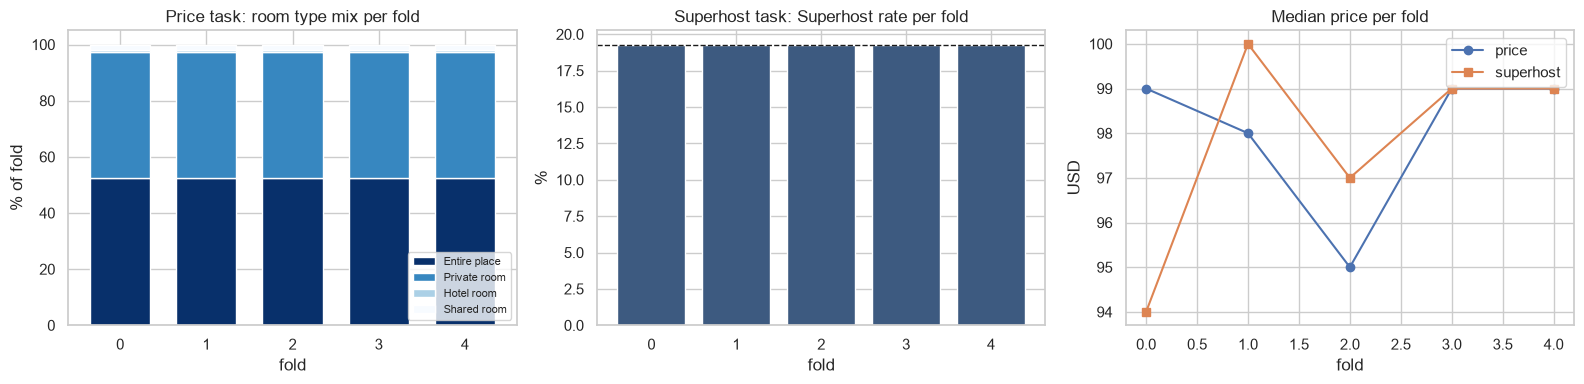

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
rp, rs = reports["price"], reports["superhost"]
rp[[f"rt {r} %" for r in ROOM_TYPES]].plot.bar(stacked=True, ax=axes[0], width=0.7, colormap="Blues_r")
axes[0].set(title="Price task: room type mix per fold", ylabel="% of fold", xlabel="fold"); axes[0].legend(ROOM_TYPES, fontsize=8, loc="lower right")
axes[1].bar(rs.index, rs["superhost_%"], color="#3D5A80"); axes[1].axhline(data["superhost"]["host_is_superhost"].mean() * 100, ls="--", c="k", lw=1)
axes[1].set(title="Superhost task: Superhost rate per fold", ylabel="%", xlabel="fold")
for ax_task, mk in [("price", "o"), ("superhost", "s")]:
    axes[2].plot(reports[ax_task].index, reports[ax_task]["median_price"], marker=mk, label=ax_task)
axes[2].set(title="Median price per fold", ylabel="USD", xlabel="fold"); axes[2].legend()
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); save(fig, "01_cv_fold_balance"); plt.show()

## 2. `host_ny_listings` uses only the host's own rows (REVIEW #11b)
`host_ny_listings` = number of the host's listings in the data at the scrape snapshot, **including the current listing**. It is computed by `groupby("host_id")`, so it should depend only on rows of the same host. Because CV is host-grouped, that means a validation row never borrows information from the fitting folds. Three checks:
1. same value when computed on the full data, on the training part, and on the rows of each fold's hosts;
2. unchanged when all prices are replaced (no target information);
3. unchanged when the rows of all other hosts are removed (no other-host information) — covered by check 1 at fold level.

**Limitation (documented):** it is a snapshot-time count, so it may include listings created after the target listing; it is not "the number of listings known when this listing was created".

In [5]:
full_val = build_features(df).set_index("listing_id")["host_ny_listings"]
train_val = ft.set_index("listing_id")["host_ny_listings"]
checks = [{"check": "train part vs full data", "rows": len(train_val),
           "mismatches": int((train_val != full_val.loc[train_val.index]).sum())}]
for task, d in data.items():
    a = assignments[task]
    for k in range(5):
        hosts_k = set(a.loc[a["fold"] == k, "host_id"])
        sub = build_features(train[train["host_id"].isin(hosts_k)]).set_index("listing_id")["host_ny_listings"]
        checks.append({"check": f"{task} fold {k}: only this fold's hosts", "rows": len(sub),
                       "mismatches": int((sub != full_val.loc[sub.index]).sum())})
no_target = build_features(train.assign(**{TARGET: 0})).set_index("listing_id")["host_ny_listings"]
checks.append({"check": "all prices set to 0", "rows": len(no_target),
               "mismatches": int((no_target != train_val.loc[no_target.index]).sum())})
inv = pd.DataFrame(checks)
print(inv.to_string(index=False))
assert inv["mismatches"].sum() == 0, "host_ny_listings depends on rows outside the host"
inv.to_csv(TABLE_DIR / "08_host_ny_listings_invariance.csv", index=False)

                                   check  rows  mismatches
                 train part vs full data 29609           0
    price fold 0: only this fold's hosts  5919           0
    price fold 1: only this fold's hosts  5921           0
    price fold 2: only this fold's hosts  5917           0
    price fold 3: only this fold's hosts  5917           0
    price fold 4: only this fold's hosts  5917           0
superhost fold 0: only this fold's hosts  5919           0
superhost fold 1: only this fold's hosts  5919           0
superhost fold 2: only this fold's hosts  5919           0
superhost fold 3: only this fold's hosts  5918           0
superhost fold 4: only this fold's hosts  5919           0
                     all prices set to 0 29609           0


## 3. Duplicate feature rows (leakage checklist item)
Identical model inputs in the fitting and validation parts can make CV look better than it is. Duplicates **within one host** are harmless here (the host is never split). We count rows whose model inputs (the primary feature columns, amenity list sorted; identifiers excluded) are identical, and how many of those duplicate groups span **different hosts** and **different folds**. Identical inputs can also be legitimate (two genuinely similar flats), so this is a diagnostic.

In [6]:
dup_rows = []
for task, d in data.items():
    cols = spec_columns(feature_spec(task, "primary"))
    key = d[cols].copy()
    key["amenity_list"] = key["amenity_list"].apply(lambda a: "|".join(sorted(a)))
    gid = pd.util.hash_pandas_object(key.astype(str), index=False)
    g = pd.DataFrame({"gid": gid.to_numpy(), "host_id": d["host_id"].to_numpy(),
                      "fold": assignments[task]["fold"].to_numpy(), "price": d[TARGET].to_numpy()})
    g = g[g["gid"].duplicated(keep=False)]
    per = g.groupby("gid").agg(size=("host_id", "size"), hosts=("host_id", "nunique"),
                               folds=("fold", "nunique"), prices=("price", "nunique"))
    cross_fold = per[per["folds"] > 1]
    dup_rows.append({"task": task, "input_cols": len(cols), "rows_in_duplicate_groups": len(g),
                     "share_%": round(len(g) / len(d) * 100, 2), "groups": len(per),
                     "groups_multi_host": int((per["hosts"] > 1).sum()),
                     "groups_cross_fold": len(cross_fold), "rows_in_cross_fold_groups": int(cross_fold["size"].sum()),
                     "cross_fold_groups_same_price": int((cross_fold["prices"] == 1).sum())})
dup_tab = pd.DataFrame(dup_rows)
print(dup_tab.to_string(index=False))
dup_tab.to_csv(TABLE_DIR / "08_duplicate_inputs.csv", index=False)

     task  input_cols  rows_in_duplicate_groups  share_%  groups  groups_multi_host  groups_cross_fold  rows_in_cross_fold_groups  cross_fold_groups_same_price
    price          28                       198     0.67      50                  0                  0                          0                             0
superhost          22                       198     0.67      50                  0                  0                          0                             0


## 4. Baselines in the same folds
A model is only useful if it beats a rule that ignores all features. For the price model the rule is "always predict the median log price of the fitting folds" (`DummyRegressor(strategy="median")`), which back-transforms to the typical price. For Superhost, `DummyClassifier(strategy="prior")` always outputs the training prevalence: ROC-AUC = 0.5 and PR-AUC ≈ prevalence by construction, recall/F1 = 0 at threshold 0.5. `strategy="stratified"` (random labels with the training prevalence) gives reference values for recall/F1.

In [7]:
# --- Price task ---
Xp = data["price"][spec_columns(feature_spec("price"))]
yp = np.log1p(data["price"][TARGET])
folds_p = load_folds(data["price"], "price")
res_p, _ = evaluate_cv(DummyRegressor(strategy="median"), Xp, yp, folds_p, "price")
print("Dummy median - price, per fold"); print(res_p.round(4).to_string(index=False))

# --- Superhost task ---
Xs = data["superhost"][spec_columns(feature_spec("superhost"))]
ys = data["superhost"]["host_is_superhost"].astype(int)
folds_s = load_folds(data["superhost"], "superhost")
res_prior, _ = evaluate_cv(DummyClassifier(strategy="prior"), Xs, ys, folds_s, "superhost")
res_strat, _ = evaluate_cv(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE), Xs, ys, folds_s, "superhost")
print("\nDummy prior - superhost, per fold"); print(res_prior.round(4).to_string(index=False))

base_p = pd.DataFrame([summarize(res_p, "DummyRegressor(median)")])
base_s = pd.DataFrame([summarize(res_prior, "DummyClassifier(prior)"), summarize(res_strat, "DummyClassifier(stratified)")])
print("\n=== Baselines (mean and SD over 5 host-grouped folds) ===")
print(base_p.round(4).T.to_string()); print(); print(base_s.round(4).T.to_string())
target_30 = base_p["log_rmse_mean"].iloc[0] * 0.70
print(f"\nAspirational price target (D5): log-RMSE <= {target_30:.4f} (30% below the baseline {base_p['log_rmse_mean'].iloc[0]:.4f})")
base_p.to_csv(TABLE_DIR / "08_baselines_price.csv", index=False); base_s.to_csv(TABLE_DIR / "08_baselines_superhost.csv", index=False)

Dummy median - price, per fold
 fold  n_val  log_rmse  mae_usd  medae_usd  r2_log  rmse_usd  seconds
    0   5918    0.7168  82.9953       43.0 -0.0073  249.0389     0.01
    1   5918    0.6914  79.3647       40.0 -0.0028  280.6970     0.00
    2   5917    0.7060  75.2204       44.0 -0.0000  216.6259     0.00
    3   5917    0.7214  82.8739       44.0 -0.0010  330.9565     0.00
    4   5917    0.7250  85.1276       44.0 -0.0003  340.5379     0.00

Dummy prior - superhost, per fold
 fold  n_val  roc_auc  pr_auc  recall  precision  f1  prevalence  seconds
    0   5919      0.5  0.1929     0.0        0.0 0.0      0.1929     0.01
    1   5919      0.5  0.1929     0.0        0.0 0.0      0.1929     0.01
    2   5919      0.5  0.1928     0.0        0.0 0.0      0.1928     0.01
    3   5918      0.5  0.1928     0.0        0.0 0.0      0.1928     0.01
    4   5919      0.5  0.1929     0.0        0.0 0.0      0.1929     0.01

=== Baselines (mean and SD over 5 host-grouped folds) ===
           

In [8]:
# --- src tests (incl. cv_utils) ---
from importlib import reload
import src.cv_utils, tests.test_src as tsrc; reload(src.cv_utils); reload(tsrc)
print(tsrc.run_all().to_string(index=False))

                                                    test result error
                                    test_find_tf_columns   PASS      
                              test_to_bool_keeps_missing   PASS      
                              test_parse_amenities_valid   PASS      
                          test_parse_amenities_bad_input   PASS      
                                     test_missing_report   PASS      
                        test_checker_finds_duplicate_ids   PASS      
                      test_checker_range_ignores_missing   PASS      
                      test_checker_unknown_column_raises   PASS      
                      test_checker_rejects_non_dataframe   PASS      
                           test_assert_clean_strict_mode   PASS      
                           test_load_missing_file_raises   PASS      
                   test_train_test_uses_saved_assignment   PASS      
            test_attach_split_rejects_unassigned_listing   PASS      
                    

## Part A – findings
**Folds (saved, reused by all models of a task):**
- **Price task:** 29,587 rows / 21,392 hosts. Fold sizes are 5,917–5,918 and **host overlap is 0** in every fold. The room-type mix is practically identical across folds (entire places 52.43–52.46%, private rooms 44.96–44.97%). Borough shares vary more (Manhattan 43.3–47.7%, Brooklyn 36.7–40.5%), because whole hosts are moved and boroughs were not stratified. The Superhost rate varies between 17.9% and 22.1% (not a stratification variable here). The median price is \$95–99 per fold, and the largest single host covers at most 3.1% of a fold.
- **Superhost task:** 29,594 rows / 21,397 hosts. The Superhost rate is 19.28–19.29% in every fold (stratified), host overlap is 0, and the room-type and borough mixes stay close (entire places 51.7–53.2%).
- These are diagnostics. The folds are kept as drawn, not re-drawn for nicer numbers.

**`host_ny_listings`:** 0 mismatches in all 12 checks: full data vs train; each fold's hosts alone, for both tasks; all prices replaced. The feature uses only the host's own rows and no target information, so it cannot carry information across host-grouped folds. It remains a **snapshot-time** count (documented limitation).

**Duplicate inputs:** 198 rows (0.67%) fall into 50 groups with identical model inputs. **All groups belong to a single host**, so they are never split between fitting and validation folds. There are no cross-host or cross-fold duplicates.

**Baselines (5 host-grouped folds, mean ± SD):**
- **Price:** `DummyRegressor(median)`: log-RMSE **0.712 ± 0.014**, MAE \$81 ± 4, MedAE \$43, R² (log) ≈ 0, RMSE \$284 ± 53. The large RMSE spread comes from the price tail (D15). The D5 aspirational target is therefore **log-RMSE ≤ 0.499**.
- **Superhost:** `DummyClassifier(prior)`: ROC-AUC 0.500, PR-AUC 0.193 (= prevalence), recall/F1 0. `stratified`: F1 0.189, recall 0.188. These are the reference values for S11.

**Tests:** 20/20 `src` tests pass (2 new for `cv_utils`).

**Next (Part B):** random vs host-grouped CV for both tasks with two reference models, to show how much a random split would overstate performance.

# Part B – Random vs host-grouped CV (REVIEW #11: both tasks)
**Why:** 38% of listings belong to hosts with several listings, and those siblings often share prices, locations, descriptions and — for Superhost — the label itself. A random K-fold puts siblings on both sides, so the model can partly "recognise the host" instead of learning what generalises to new hosts. Our evaluation scenario is **unseen hosts** (D13), so the host-grouped folds are the honest ones.

**Design:** the same two untuned reference models per task, the same preprocessing (fitted inside each fold), the same 5-fold size; only the fold scheme changes.
- Price: `Ridge(alpha=1)` on the `scaled` family and `RandomForestRegressor` on the `tree` family; random scheme = `KFold(5, shuffle=True, random_state=42)`.
- Superhost: `LogisticRegression` (L2, the classification counterpart of Ridge) on `scaled` and `RandomForestClassifier` on `tree`; random scheme = `StratifiedKFold(5, shuffle=True, random_state=42)`.

The gap is reported **descriptively** for these models and this data, not as a general estimate of leakage. These reference models are **not** the S9–S11 results (no tuning, no model choice here).

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import KFold, StratifiedKFold
from src.preprocess import make_preprocessor
from src.cv_utils import classification_metrics, regression_metrics

def ref_models(task):
    # untuned reference models; each is a full Pipeline, so preprocessing is re-fitted inside every fold
    spec = feature_spec(task, "primary")
    rf_args = dict(n_estimators=200, max_features="sqrt", min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    if task == "price":
        return {"Ridge (scaled)": Pipeline([("pre", make_preprocessor("scaled", spec)), ("model", Ridge(alpha=1.0))]),
                "RandomForest (tree)": Pipeline([("pre", make_preprocessor("tree", spec)), ("model", RandomForestRegressor(**rf_args))])}
    return {"Logistic L2 (scaled)": Pipeline([("pre", make_preprocessor("scaled", spec)), ("model", LogisticRegression(C=1.0, max_iter=3000))]),
            "RandomForest (tree)": Pipeline([("pre", make_preprocessor("tree", spec)), ("model", RandomForestClassifier(**rf_args))])}

task_xy = {"price": (Xp, yp, folds_p), "superhost": (Xs, ys, folds_s)}
random_folds = {"price": list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(Xp)),
                "superhost": list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(Xs, ys))}

# how often does a validation row's host also appear in the fitting part?
seen_flag, expo = {}, []
for task in task_xy:
    hosts = data[task]["host_id"].to_numpy(); seen = np.zeros(len(hosts), bool)
    for scheme, folds in [("random", random_folds[task]), ("host-grouped", task_xy[task][2])]:
        share = []
        for tr, va in folds:
            s = np.isin(hosts[va], hosts[tr]); share.append(s.mean() * 100)
            if scheme == "random": seen[va] = s
        expo.append({"task": task, "scheme": scheme, "val rows with host in fitting part, % (mean)": np.mean(share),
                     "min": np.min(share), "max": np.max(share)})
    seen_flag[task] = seen
print(pd.DataFrame(expo).round(2).to_string(index=False))

     task       scheme  val rows with host in fitting part, % (mean)   min   max
    price       random                                         35.18 34.46 35.81
    price host-grouped                                          0.00  0.00  0.00
superhost       random                                         35.03 33.76 36.05
superhost host-grouped                                          0.00  0.00  0.00


In [10]:
# --- 2 tasks x 2 models x 2 schemes x 5 folds = 40 fits (RandomForest takes most of the time) ---
results, oofs = [], {}
for task, (X, y, gfolds) in task_xy.items():
    for mname, est in ref_models(task).items():
        for scheme, folds in [("random", random_folds[task]), ("host-grouped", gfolds)]:
            per, oof = evaluate_cv(est, X, y, folds, task)
            s = summarize(per, f"{task} | {mname} | {scheme}")
            results.append({"task": task, "model": mname, "scheme": scheme, **s.to_dict()})
            oofs[(task, mname, scheme)] = oof
            print(f"{task:>9} | {mname:<22} | {scheme:<12} | {s['seconds_total']:6.1f}s", flush=True)
res_b = pd.DataFrame(results)

    price | Ridge (scaled)         | random       |    0.9s
    price | Ridge (scaled)         | host-grouped |    0.9s
    price | RandomForest (tree)    | random       |    4.3s
    price | RandomForest (tree)    | host-grouped |    4.4s
superhost | Logistic L2 (scaled)   | random       |    2.5s
superhost | Logistic L2 (scaled)   | host-grouped |    2.7s
superhost | RandomForest (tree)    | random       |    4.4s
superhost | RandomForest (tree)    | host-grouped |    3.9s


In [11]:
METRICS = {"price": ["log_rmse", "mae_usd", "medae_usd", "r2_log"], "superhost": ["roc_auc", "pr_auc"]}
dummy_lr = base_p["log_rmse_mean"].iloc[0]
rows = []
for (task, mname), g in res_b.groupby(["task", "model"], sort=False):
    g = g.set_index("scheme")
    for m in METRICS[task]:
        r, gr = g.loc["random", f"{m}_mean"], g.loc["host-grouped", f"{m}_mean"]
        rows.append({"task": task, "model": mname, "metric": m,
                     "random CV": r, "random SD": g.loc["random", f"{m}_sd"],
                     "grouped CV": gr, "grouped SD": g.loc["host-grouped", f"{m}_sd"],
                     "gap (random - grouped)": r - gr, "gap % of grouped": (r - gr) / abs(gr) * 100})
gap_tab = pd.DataFrame(rows)
print(gap_tab.round(4).to_string(index=False))
gap_tab.round(5).to_csv(TABLE_DIR / "08_random_vs_grouped.csv", index=False)

print("\nPrice: improvement in log-RMSE over the Dummy median baseline (0.712)")
for _, r in gap_tab[gap_tab.metric == "log_rmse"].iterrows():
    print(f"  {r['model']:<22} random CV {1 - r['random CV'] / dummy_lr:6.1%} | host-grouped CV {1 - r['grouped CV'] / dummy_lr:6.1%}")

     task                model    metric  random CV  random SD  grouped CV  grouped SD  gap (random - grouped)  gap % of grouped
    price       Ridge (scaled)  log_rmse     0.4525     0.0101      0.4596      0.0077                 -0.0071           -1.5538
    price       Ridge (scaled)   mae_usd    56.5557     2.4659     57.2297      3.2575                 -0.6739           -1.1776
    price       Ridge (scaled) medae_usd    23.3054     0.2440     23.7561      0.6949                 -0.4507           -1.8973
    price       Ridge (scaled)    r2_log     0.5957     0.0102      0.5820      0.0208                  0.0136            2.3445
    price  RandomForest (tree)  log_rmse     0.4248     0.0116      0.4598      0.0076                 -0.0350           -7.6136
    price  RandomForest (tree)   mae_usd    53.4152     2.5707     57.3092      3.2655                 -3.8939           -6.7946
    price  RandomForest (tree) medae_usd    20.4355     0.3749     23.4380      0.7952           

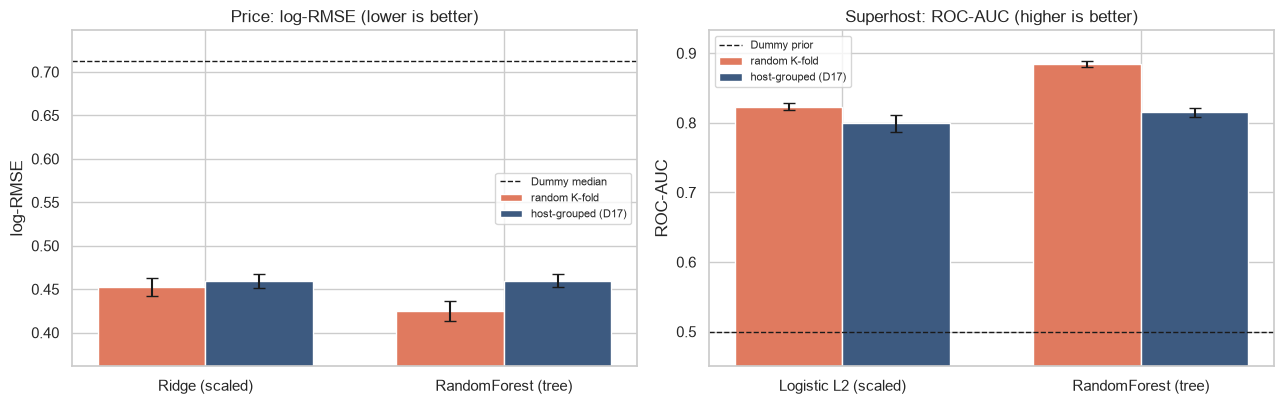

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, task, m, ref, lab in [(axes[0], "price", "log_rmse", dummy_lr, "Dummy median"),
                              (axes[1], "superhost", "roc_auc", 0.5, "Dummy prior")]:
    g = gap_tab[(gap_tab.task == task) & (gap_tab.metric == m)].reset_index(drop=True)
    x = np.arange(len(g)); w = 0.36
    ax.bar(x - w / 2, g["random CV"], w, yerr=g["random SD"], capsize=4, color="#E07A5F", label="random K-fold")
    ax.bar(x + w / 2, g["grouped CV"], w, yerr=g["grouped SD"], capsize=4, color="#3D5A80", label="host-grouped (D17)")
    ax.axhline(ref, ls="--", c="k", lw=1, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(g["model"]); ax.legend(fontsize=8)
    lo = min(g["random CV"].min(), g["grouped CV"].min())
    ax.set_ylim(lo * 0.85 if task == "price" else 0.45, None)
axes[0].set(title="Price: log-RMSE (lower is better)", ylabel="log-RMSE")
axes[1].set(title="Superhost: ROC-AUC (higher is better)", ylabel="ROC-AUC")
plt.tight_layout(); save(fig, "02_random_vs_grouped_cv"); plt.show()

### Where does the random-CV optimism come from?
Under random K-fold, split the out-of-fold predictions into rows whose **host also appears in the fitting part** and rows whose host does not. Caveat: the two groups are not comparable populations (seen hosts are mostly multi-listing, often professional hosts), so this shows the mechanism, not a clean causal effect. As a control, the **same listings** are also scored with their host-grouped OOF predictions: if the "seen" rows lose much more accuracy than the "unseen" rows when we switch to grouped CV, the optimism comes from recognising the host.

In [13]:
rows = []
for task, (X, y, _) in task_xy.items():
    yv, seen = y.to_numpy(), seen_flag[task]
    for mname in ref_models(task):
        for scheme in ["random", "host-grouped"]:
            oof = oofs[(task, mname, scheme)]
            for label, mask in [("host seen in fitting part", seen), ("host unseen", ~seen)]:
                met = regression_metrics(yv[mask], oof[mask]) if task == "price" else classification_metrics(yv[mask], oof[mask])
                keep = ["log_rmse", "mae_usd"] if task == "price" else ["roc_auc", "pr_auc", "prevalence"]
                rows.append({"task": task, "model": mname, "scheme": scheme, "rows (by random-CV status)": label,
                             "n": int(mask.sum()), **{k: round(met[k], 4) for k in keep}})
seen_tab = pd.DataFrame(rows)
print(seen_tab.to_string(index=False))
seen_tab.to_csv(TABLE_DIR / "08_random_cv_seen_unseen.csv", index=False)

     task                model       scheme rows (by random-CV status)     n  log_rmse  mae_usd  roc_auc  pr_auc  prevalence
    price       Ridge (scaled)       random  host seen in fitting part 10409    0.4564  53.6091      NaN     NaN         NaN
    price       Ridge (scaled)       random                host unseen 19178    0.4505  58.1551      NaN     NaN         NaN
    price       Ridge (scaled) host-grouped  host seen in fitting part 10409    0.4747  55.3811      NaN     NaN         NaN
    price       Ridge (scaled) host-grouped                host unseen 19178    0.4513  58.2330      NaN     NaN         NaN
    price  RandomForest (tree)       random  host seen in fitting part 10409    0.3740  44.3509      NaN     NaN         NaN
    price  RandomForest (tree)       random                host unseen 19178    0.4502  58.3351      NaN     NaN         NaN
    price  RandomForest (tree) host-grouped  host seen in fitting part 10409    0.4772  55.4566      NaN     NaN         NaN


## Part B – findings
**Exposure:** under random K-fold, **35%** of validation rows have their host in the fitting part (34.5–36.1% per fold). Under the host-grouped folds this is 0%.

**Price (log-RMSE, mean ± SD over 5 folds):**

| model | random K-fold | host-grouped | optimism |
|---|---|---|---|
| Ridge (scaled) | 0.453 ± 0.010 | 0.460 ± 0.008 | 1.6% |
| RandomForest (tree) | 0.425 ± 0.012 | 0.460 ± 0.008 | 7.6% (MedAE \$20.4 vs \$23.4, −13%) |

- Random CV would make the forest look clearly better than Ridge (0.425 vs 0.453). Under host-grouped CV the two untuned models are **tied** (0.4598 vs 0.4596).
- The fold scheme therefore changes the **model ranking**, not just the level. This is the strongest reason for D17.

**Superhost:**

| model | ROC-AUC random | ROC-AUC grouped | PR-AUC random | PR-AUC grouped |
|---|---|---|---|---|
| Logistic L2 (scaled) | 0.823 | 0.800 | 0.502 | 0.462 |
| RandomForest (tree) | 0.884 | 0.815 | 0.683 | 0.491 |

- The forest's PR-AUC is overstated by **39%** under random CV.
- As expected, the gap is much larger than for price, because the label is a host attribute shared by all of the host's listings.

**Mechanism (same listings, two schemes):**
- For rows whose host is **unseen** under random CV, the scores are practically identical in both schemes. Forest log-RMSE is 0.450 vs 0.450; forest ROC-AUC is 0.850 vs 0.849.
- All of the optimism sits in the **seen-host** rows. For the forest:
  - price log-RMSE 0.374 → 0.477;
  - Superhost ROC-AUC 0.925 → 0.743;
  - PR-AUC 0.843 → 0.487.
- Flexible models memorise host-specific patterns from sibling listings. Ridge, being less flexible, gains much less (price 0.456 → 0.475).

**Sanity check (leakage checklist):**
- Even untuned grouped models beat the price baseline by **35%** (log-RMSE 0.460 vs 0.712). The D5 aspirational target of 30% was therefore conservative; the real question in S9–S10 is how far beyond 0.46 we can go.
- Superhost ROC-AUC is about 0.80–0.82.
- Neither result is close to the audit thresholds (> 60% improvement, ROC-AUC > 0.95).
- These reference results are diagnostics only. They are not S9–S11 model results.

**Next (Part C):** imputation options compared by host-grouped CV (Ridge, `scaled` family): median + flag vs KNN vs ExtraTrees-iterative, and bedrooms median vs 0.

# Part C – Imputation options compared by CV (REVIEW #11, Tier 2 approved)
The S7 masking experiment ranked ExtraTrees-iterative and KNN above the median for **randomly hidden** values. Real missingness is not random (e.g. studios without a bedroom count, inactive hosts). The question that matters is therefore: **does a smarter imputer improve the model's out-of-sample error?** We answer it with the D17 host-grouped folds.

- **Model:** the linear model of the `scaled` family (Ridge for price, L2 logistic regression for Superhost). Linear models are the most sensitive to imputed values; tree models keep median + flags (S10 may also use native NaN handling).
- **Variants:**
  1. median + missing flags (D16, current);
  2. median, but `bedrooms` missing → 0 (studio hypothesis; an experiment, not an assumed truth);
  3. `KNNImputer(k=5)`;
  4. `IterativeImputer` with ExtraTrees.
  Variants 3 and 4 impute all numeric columns jointly after clipping, log1p and **standardization**, so KNN distances are not dominated by large-scale columns. Missing flags are present in every variant, so only the filled values differ.
- **Decision rule:** keep variant 1 unless an alternative is better by **more than one standard error of the fold-wise paired difference** (primary metric: log-RMSE / ROC-AUC). With 5 folds the SE is rough, so small differences are not over-interpreted.
- **Limitation:** the multivariate imputers only use the numeric block (not room type or borough) to fill values.

In [14]:
from src.cv_utils import paired_comparison
num_cols = lambda task: [c for g in ["skewed", "bedrooms", "numeric"] for c in feature_spec(task)[g]]
miss = pd.DataFrame({task: task_xy[task][0][num_cols(task)].isna().mean() * 100 for task in task_xy}).round(2)
print("Missing share (%) of the numeric inputs (training part)"); print(miss.fillna("not used").to_string())

Missing share (%) of the numeric inputs (training part)
                        price superhost
accommodates             0.00      0.03
bedrooms                 9.84      9.91
host_acceptance_rate    39.47  not used
host_ny_listings         0.00       0.0
host_response_rate      49.92  not used
host_response_time_ord  49.92  not used
host_tenure_days         0.05       0.0
latitude                 0.00       0.0
longitude                0.00       0.0
maximum_nights_capped    0.00       0.0
minimum_nights_capped    0.00       0.0
n_amenities              0.00       0.0


In [15]:
VARIANTS = {"median + flags (D16)": dict(imputer="median", bedrooms_fill="median"),
            "median, bedrooms = 0": dict(imputer="median", bedrooms_fill="zero"),
            "KNN (k=5)": dict(imputer="knn"),
            "ExtraTrees iterative": dict(imputer="iterative")}

def linear_model(task, **kw):
    spec = feature_spec(task, "primary")
    model = Ridge(alpha=1.0) if task == "price" else LogisticRegression(C=1.0, max_iter=3000)
    return Pipeline([("pre", make_preprocessor("scaled", spec, random_state=RANDOM_STATE, **kw)), ("model", model)])

imp_per, imp_oof = {}, {}
for task, (X, y, gfolds) in task_xy.items():
    for vname, kw in VARIANTS.items():
        per, oof = evaluate_cv(linear_model(task, **kw), X, y, gfolds, task)
        imp_per[(task, vname)], imp_oof[(task, vname)] = per, oof
        print(f"{task:>9} | {vname:<22} | {per['seconds'].sum():6.1f}s", flush=True)

    price | median + flags (D16)   |    0.9s
    price | median, bedrooms = 0   |    0.9s
    price | KNN (k=5)              |   83.1s


/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


    price | ExtraTrees iterative   |   32.5s
superhost | median + flags (D16)   |    2.7s
superhost | median, bedrooms = 0   |    2.4s
superhost | KNN (k=5)              |   10.8s


/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


superhost | ExtraTrees iterative   |   23.2s


In [16]:
PRIMARY = {"price": ("log_rmse", "lower"), "superhost": ("roc_auc", "higher")}
SECOND = {"price": ["mae_usd", "medae_usd"], "superhost": ["pr_auc"]}
BASE = "median + flags (D16)"
rows = []
for task in task_xy:
    m, direction = PRIMARY[task]
    base = imp_per[(task, BASE)][m]
    for vname in VARIANTS:
        per = imp_per[(task, vname)]
        row = {"task": task, "variant": vname, "metric": m, "mean": per[m].mean(), "fold SD": per[m].std(ddof=1)}
        row.update({f"{s} mean": per[s].mean() for s in SECOND[task]})
        if vname != BASE:
            pc = paired_comparison(per[m], base)
            gain = -pc["mean_diff"] if direction == "lower" else pc["mean_diff"]     # > 0 means the alternative is better
            row.update({"diff vs D16 (alt - base)": pc["mean_diff"], "SE paired diff": pc["se_diff"],
                        "gain in SE units": gain / pc["se_diff"], "better by > 1 SE": bool(gain > pc["se_diff"])})
        row["seconds (5 folds)"] = per["seconds"].sum()
        rows.append(row)
imp_tab = pd.DataFrame(rows)
print(imp_tab.round(5).to_string(index=False))
imp_tab.round(6).to_csv(TABLE_DIR / "08_imputation_cv.csv", index=False)

     task              variant   metric    mean  fold SD  mae_usd mean  medae_usd mean  seconds (5 folds)  diff vs D16 (alt - base)  SE paired diff  gain in SE units better by > 1 SE  pr_auc mean
    price median + flags (D16) log_rmse 0.45964  0.00773      57.22966        23.75613               0.86                       NaN             NaN               NaN              NaN          NaN
    price median, bedrooms = 0 log_rmse 0.45964  0.00773      57.22978        23.74793               0.85                   0.00000         0.00000          -0.06549            False          NaN
    price            KNN (k=5) log_rmse 0.46006  0.00745      57.29154        23.89863              83.07                   0.00042         0.00021          -1.97124            False          NaN
    price ExtraTrees iterative log_rmse 0.45981  0.00766      57.23955        23.87090              32.52                   0.00017         0.00015          -1.08767            False          NaN
superhost median + f

In [17]:
# --- Where would bedrooms imputation matter? error on rows with / without a missing bedroom count (price task) ---
bm = data["price"]["bedrooms_missing"].to_numpy() == 1
yv = yp.to_numpy(); rows = []
for vname in VARIANTS:
    oof = imp_oof[("price", vname)]
    for label, mask in [("bedrooms missing", bm), ("bedrooms observed", ~bm)]:
        r = regression_metrics(yv[mask], oof[mask])
        rows.append({"variant": vname, "rows": label, "n": int(mask.sum()), "log_rmse": r["log_rmse"],
                     "mae_usd": r["mae_usd"], "mean residual (log)": float(np.mean(yv[mask] - oof[mask]))})
bed_tab = pd.DataFrame(rows)
print(bed_tab.round(4).to_string(index=False))
bed_tab.round(5).to_csv(TABLE_DIR / "08_imputation_bedrooms_rows.csv", index=False)
print("\nRoom type of listings with missing bedrooms (training part, %):")
print((data["price"].loc[bm, "room_type"].value_counts(normalize=True) * 100).round(1).to_string())

             variant              rows     n  log_rmse  mae_usd  mean residual (log)
median + flags (D16)  bedrooms missing  2911    0.4534  49.1250              -0.0061
median + flags (D16) bedrooms observed 26676    0.4604  58.1141              -0.0008
median, bedrooms = 0  bedrooms missing  2911    0.4534  49.1236              -0.0059
median, bedrooms = 0 bedrooms observed 26676    0.4604  58.1144              -0.0008
           KNN (k=5)  bedrooms missing  2911    0.4556  49.5557              -0.0085
           KNN (k=5) bedrooms observed 26676    0.4606  58.1358              -0.0008
ExtraTrees iterative  bedrooms missing  2911    0.4528  49.1425              -0.0081
ExtraTrees iterative bedrooms observed 26676    0.4606  58.1232              -0.0008

Room type of listings with missing bedrooms (training part, %):
room_type
Entire place    86.4
Private room    13.1
Hotel room       0.5


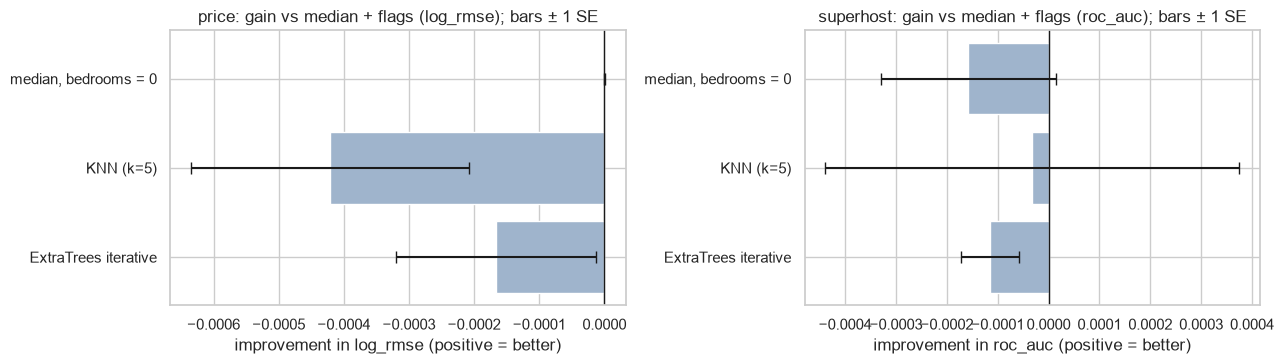

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, task in zip(axes, task_xy):
    m, direction = PRIMARY[task]
    g = imp_tab[(imp_tab.task == task) & (imp_tab.variant != BASE)].reset_index(drop=True)
    gain = -g["diff vs D16 (alt - base)"] if direction == "lower" else g["diff vs D16 (alt - base)"]
    ax.barh(g["variant"], gain, xerr=g["SE paired diff"], capsize=4,
            color=["#3D5A80" if b else "#9FB4CC" for b in g["better by > 1 SE"]])
    ax.axvline(0, c="k", lw=1); ax.invert_yaxis()
    ax.set(title=f"{task}: gain vs median + flags ({m}); bars ± 1 SE", xlabel=f"improvement in {m} (positive = better)")
plt.tight_layout(); save(fig, "03_imputation_cv"); plt.show()

## Part C – findings
**What is imputed:** for price, `bedrooms` (9.8%), the host-activity block (`host_response_rate` and `host_response_time_ord` 49.9%, `host_acceptance_rate` 39.5%) and a few `host_tenure_days`. The Superhost primary set excludes the activity block, so mostly `bedrooms` (9.9%) remains.

**Price (Ridge, log-RMSE, 5 host-grouped folds):**

| variant | log-RMSE | difference vs median + flags | SE of paired difference | better by > 1 SE? | time |
|---|---|---|---|---|---|
| median + flags (D16) | 0.45964 | – | – | – | 0.9 s |
| median, bedrooms = 0 | 0.45964 | 0.00000 | 0.00000 | no | 0.9 s |
| KNN (k=5) | 0.46006 | +0.00042 (worse) | 0.00021 | no | 84 s |
| ExtraTrees iterative | 0.45981 | +0.00017 (worse) | 0.00015 | no | 35 s |

**Superhost (logistic, ROC-AUC):** all four variants are between 0.7994 and 0.7996. None is better than median + flags; differences are at most 0.0002 with SE ≈ 0.0002.

**Why the differences are so small:**
1. Every variant includes the **missing flags**. For a linear model, flag + any constant fill is (up to regularization) the same model: the flag's coefficient absorbs the fill value. This is why bedrooms = 0 gives exactly the same score as the median.
2. Missing values are concentrated in variables with modest predictive weight. For the rows that actually have a missing bedroom count (2,911), the errors are almost the same for all variants (log-RMSE 0.453–0.456).

The S7 masking advantage of KNN/ExtraTrees (more accurate filled values under random masking) does **not** translate into better predictions.

**Studio hypothesis:** 86.4% of listings with a missing bedroom count are entire places (vs 52.4% overall). This is consistent with studios, but CV cannot confirm it, and for linear models with a flag it makes no difference.

**Decision D18 (Tier 2, pre-registered rule from REVIEW #11):** keep **median + missing flags** (D16) for the `ols`/`scaled` families. It is the simplest and fastest variant, and no alternative is better by more than 1 SE. The `knn`/`iterative` options stay available in `make_preprocessor` for reproducibility of this comparison. The `ConvergenceWarning` of IterativeImputer (5 iterations) does not affect the conclusion.

# Part D – Leakage checklist (REVIEW #11)
Programmatic checks where possible, otherwise the evidence from Parts A–C. Status: **OK** = verified here, **PLANNED** = enforced in a later stage, **LIMITATION** = accepted and documented.

In [19]:
price_cols = spec_columns(feature_spec("price", "primary"))
sh_cols = spec_columns(feature_spec("superhost", "primary"))
sh_abl_cols = spec_columns(feature_spec("superhost", "ablation"))
review_like = [c for c in set(price_cols + sh_abl_cols) if c.startswith(("review", "n_reviews", "reviews", "number_of_reviews", "first_review", "last_review", "has_reviews"))]
ACTIVITY = ["host_response_rate", "host_acceptance_rate", "host_response_time_ord", "host_activity_missing", "acceptance_missing"]
X_checks = {
    "target not an input (price)": TARGET not in price_cols + sh_abl_cols,
    "target not an input (superhost)": "host_is_superhost" not in sh_cols + sh_abl_cols,
    "no review-score / review-activity inputs in primary or ablation specs used here": not review_like,
    "host-activity block absent from Superhost primary": not set(ACTIVITY) & set(sh_cols),
    "host_id / listing_id not inputs": not {"host_id", "listing_id"} & set(price_cols + sh_abl_cols),
}
print(pd.Series(X_checks).to_string())
assert all(X_checks.values())

checklist = pd.DataFrame([
    ("Test set never used for fitting or exploration", "OK", "notebook loads only the train part (train_test -> train, _); folds built on train only; test locked until S14 (D13)"),
    ("Hosts never split between fitting and validation folds", "OK", "host overlap 0 in all 10 folds (Part A); check_folds raises otherwise"),
    ("Same folds for every model of a task", "OK", "persisted data/splits/cv_folds_<task>.csv + manifest; load_folds"),
    ("All learned preprocessing fitted inside folds", "OK", "evaluate_cv clones the full Pipeline per fold (imputers, clip bounds, scaler, one-hot vocabularies, amenity vocabulary); unit tests for fit-only behaviour"),
    ("No target encoding / no target-derived inputs", "OK", "make_preprocessor has no target encoder; price and host_is_superhost not inputs of their own task (checks above)"),
    ("No post-stay / review information in primary models", "OK", "review_scores_* and review-activity columns not in the specs (D7); has_reviews ablation-only"),
    ("Superhost primary excludes the host-activity block", "OK", "check above (REVIEW #10); ablation keeps it"),
    ("host_ny_listings uses only the host's own rows", "OK / LIMITATION", "0 mismatches in 12 invariance checks; snapshot-time count incl. current listing (may include later listings)"),
    ("host_is_superhost in the price model", "LIMITATION", "kept per D7; assumed observable at the pricing decision point; separate ablation in S9"),
    ("Duplicate inputs across hosts / folds", "OK", "198 rows in 50 identical-input groups, all single-host; 0 cross-host, 0 cross-fold"),
    ("Random-CV optimism quantified", "OK", "random K-fold overstates forest PR-AUC by 39% and log-RMSE by 7.6%; host-grouped folds used (Part B)"),
    ("Suspiciously good scores", "OK", "reference models: price -35% vs baseline (audit threshold -60%), ROC-AUC 0.80-0.82 (threshold 0.95)"),
    ("Hyperparameter selection optimism", "LIMITATION", "tuning and comparison on the same folds, no nested CV; locked test set gives the final estimate"),
    ("Classification threshold", "PLANNED (S11)", "chosen on train OOF predictions, frozen before S14; OOF max-F1 not reported as unbiased"),
    ("Imputation choice", "OK", "chosen by host-grouped CV with the pre-registered 1-SE rule (Part C, D18)"),
], columns=["item", "status", "evidence"])
print(checklist.to_string(index=False))
checklist.to_csv(TABLE_DIR / "08_leakage_checklist.csv", index=False)

target not an input (price)                                                        True
target not an input (superhost)                                                    True
no review-score / review-activity inputs in primary or ablation specs used here    True
host-activity block absent from Superhost primary                                  True
host_id / listing_id not inputs                                                    True
                                                  item          status                                                                                                                                                   evidence
        Test set never used for fitting or exploration              OK                                        notebook loads only the train part (train_test -> train, _); folds built on train only; test locked until S14 (D13)
Hosts never split between fitting and validation folds              OK                                      

## S8 – Evaluation
**What we did**
1. **D17 (Tier 3, REVIEW #11/#11b, student approved): validation scheme.** Host-grouped, stratified 5-fold CV on the training part, one persisted assignment per task. It is shared by all models of a task, so S9–S11 comparisons are paired and fair.
2. **Infrastructure:** `src/cv_utils.py` (folds, metrics, `evaluate_cv`, paired comparison) and a multivariate-imputer option in `make_preprocessor`. 21/21 `src` tests pass.
3. **Baselines** in the same folds, plus **random vs grouped CV** for both tasks.
4. **Imputation compared by CV**, recorded as **D18**.
5. **Leakage checklist.**

**Findings**
- **Baselines:**
  - Price: log-RMSE **0.712** (MAE \$81, MedAE \$43). The D5 target of ≥ 30% improvement means log-RMSE ≤ 0.499.
  - Superhost: ROC-AUC 0.500 and PR-AUC 0.193.
- **Untuned reference models under host-grouped CV:**
  - Price: Ridge and RandomForest both reach log-RMSE ≈ **0.460**, 35% better than the baseline. So the 30% target is already met; the S9–S10 question is how much further we can go.
  - Superhost: ROC-AUC 0.80 (logistic) and 0.82 (forest), PR-AUC 0.46–0.49.
- **Random K-fold is misleading here.** About 35% of validation rows share a host with the fitting part.
  - Random CV makes the forest look clearly better than Ridge for price (0.425 vs 0.453), but they are tied under grouped CV. It also overstates the forest's Superhost PR-AUC by 39% (0.683 vs 0.491).
  - All of the optimism comes from listings whose host was seen: on unseen-host rows both schemes agree.
  - Flexible models (forests, and later boosting/KNN) benefit most from this kind of host memorisation, which is why grouped CV matters most for S10–S11.
- **Imputation:** KNN and ExtraTrees-iterative do not beat median + flags (differences ≤ 0.0004 log-RMSE, at most 2 SE **worse**). bedrooms = 0 is equivalent for linear models because of the missing flag.

**Decisions:** D17 (Tier 3, approved), D18 (Tier 2: keep median + flags, pre-registered rule).

**Limitations:**
- Five folds give rough SEs, so small differences should not be over-interpreted.
- No nested CV, so tuned CV scores are slightly optimistic.
- `host_ny_listings` is a snapshot-time count.
- Keeping `host_is_superhost` in the price model assumes the badge is visible at pricing time.
- The multivariate imputers only used the numeric block.

**Next step – S9 (ML II, linear family):**
- Models in course order: OLS (`ols` family), PCR, PLS, Ridge, Lasso and ElasticNet (`scaled`). Each follows theory → model → prediction → tuning, on the persisted price folds, using the 1-SE rule on paired differences.
- Planned extras:
  - capacity nonlinearity and room type × capacity (S6);
  - target-winsorization sensitivity (D15);
  - ablations without `host_ny_listings` and without `host_is_superhost`;
  - a comparison table at the end.